In [ ]:
from os import chdir
from os.path import abspath
thepath = abspath("../base")
chdir(thepath)

In [4]:
# yaml processing file loading. 
import yaml
import numpy as np
import matplotlib.pyplot as plt
from os.path import exists, split, join, normpath, isdir

from stl import mesh
from LBC_centreline import LBC, return_LBC_centreline
from utils import array_to_o3d
from LBC_centreline import return_LBC_centreline


In [6]:
with open(f"../notebooks/plot_kwargs.yaml", "r") as f: 
    p = yaml.safe_load(f)
    f.close()

In [7]:
skeleton_kwargs = p["skeleton_kwargs"]
node_kwargs = p["node_kwargs"]
ct_kwargs = p["ct_kwargs"]
mesh_kwargs = p["mesh_kwargs"]
start_kwargs = p["start_kwargs"]
end_kwargs = p["end_kwargs"]

In [19]:
with open(f"../notebooks/conduit_map.yaml", "r") as f: 
    conduit_map = yaml.safe_load(f)
    f.close()

In [21]:
ID = 8
CONDUIT_NAME = conduit_map[ID]

In [11]:
## import the mesh data. 
mesh_fp =  f"../data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}.stl"
data = mesh.Mesh.from_file(mesh_fp)


In [12]:
lbc_centreline_fp = join(f"../temp/{ID}_{CONDUIT_NAME}/lbc/", f"{CONDUIT_NAME}_centreline.txt")

pcd = data.centroids
# convert to open3d object-
pcd = array_to_o3d(pcd)

In [13]:
with open(f"../data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}_processing.yaml", "r") as f: 
    process_p = yaml.safe_load(f)
    f.close()

In [14]:
# initialise the list containing the stages of contraction. 
skeleton_clouds = [] 
for max_it_step in range(1,6):
    # set up the Laplacian-based contraction algorithm 
    lbc = LBC(point_cloud=pcd, 
            down_sample=process_p["lbc"]["voxelSize"],
            init_attraction = process_p["lbc"]["initAttraction"], 
            init_contraction = process_p["lbc"]["initContraction"], 
            max_iteration_steps=max_it_step)
    lbc.extract_skeleton()
    skeleton_clouds.append(lbc.contracted_point_cloud)

2026-03-03 10:13:16,584 - PCD #points: 3824
Volume ratio: 1.0. Contraction weights: 171.66513525337317. Attraction weights: 2.0. Progress LBC: 100%|██████████| 1/1 [00:00<00:00,  8.41it/s]2026-03-03 10:13:16,919 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 171.66513525337317. Attraction weights: 2.0. Progress LBC: 100%|██████████| 1/1 [00:00<00:00,  4.69it/s]
2026-03-03 10:13:16,946 - PCD #points: 3824


Contraction is Done.


Volume ratio: 1.0. Contraction weights: 343.33027050674633. Attraction weights: 2.0. Progress LBC: 100%|██████████| 2/2 [00:00<00:00,  8.06it/s]2026-03-03 10:13:17,432 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 343.33027050674633. Attraction weights: 2.0. Progress LBC: 100%|██████████| 2/2 [00:00<00:00,  5.29it/s]
2026-03-03 10:13:17,456 - PCD #points: 3824


Contraction is Done.


Volume ratio: 1.0. Contraction weights: 686.6605410134927. Attraction weights: 15.03089191242926. Progress LBC: 100%|██████████| 3/3 [00:00<00:00,  7.30it/s]2026-03-03 10:13:18,160 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 686.6605410134927. Attraction weights: 15.03089191242926. Progress LBC: 100%|██████████| 3/3 [00:00<00:00,  5.05it/s]
2026-03-03 10:13:18,187 - PCD #points: 3824


Contraction is Done.


Volume ratio: 1.0. Contraction weights: 686.6605410134927. Attraction weights: 15.03089191242926. Progress LBC:  75%|███████▌  | 3/4 [00:00<00:00,  7.31it/s]2026-03-03 10:13:18,887 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 686.6605410134927. Attraction weights: 15.03089191242926. Progress LBC:  75%|███████▌  | 3/4 [00:00<00:00,  5.07it/s]
2026-03-03 10:13:18,912 - PCD #points: 3824


Contraction is Done.


Volume ratio: 1.0. Contraction weights: 686.6605410134927. Attraction weights: 15.03089191242926. Progress LBC:  60%|██████    | 3/5 [00:00<00:00,  6.96it/s]2026-03-03 10:13:19,630 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 686.6605410134927. Attraction weights: 15.03089191242926. Progress LBC:  60%|██████    | 3/5 [00:00<00:00,  4.96it/s]

Contraction is Done.


In [15]:
# definition of processing metaparameters
lbc_args = dict(init_attraction = process_p["lbc"]["initAttraction"], 
                init_contraction = process_p["lbc"]["initContraction"],
                down_sample = process_p["lbc"]["voxelSize"])

ct_args = dict(keep = True, keep_centreline = False, centreline_down_sample = process_p["lbc"]["downSample"])

In [16]:
out_LBC = return_LBC_centreline(data,
                            ct_args= ct_args,
                            lbc_args= lbc_args)

LBC_ct = out_LBC["sparse_cloud"][np.array(out_LBC["centreline"]).astype(int)]
P1 = LBC_ct[0]
P2 = LBC_ct[-1]

read file in 0.0000s


2026-03-03 10:13:22,446 - PCD #points: 3824


contracted file in 0.3725s


Volume ratio: 1.0. Contraction weights: 686.5142279426237. Attraction weights: 15.090599848817238. Progress LBC:  15%|█▌        | 3/20 [00:00<00:02,  7.49it/s]2026-03-03 10:13:23,122 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 686.5142279426237. Attraction weights: 15.090599848817238. Progress LBC:  15%|█▌        | 3/20 [00:00<00:03,  5.23it/s]

Contraction is Done.
extracted skeleton in 0.6837s
downsampled the centreline cloud in 0.0000s
49
found largest component in 0.0000s


computed minimum spanning tree in 0.4768s
created graph instance of the centreline in  0.0020s
added node coordinates to graph in  0.0000s
this minimum spanning tree has 2 leaves. Need to identify the best path.


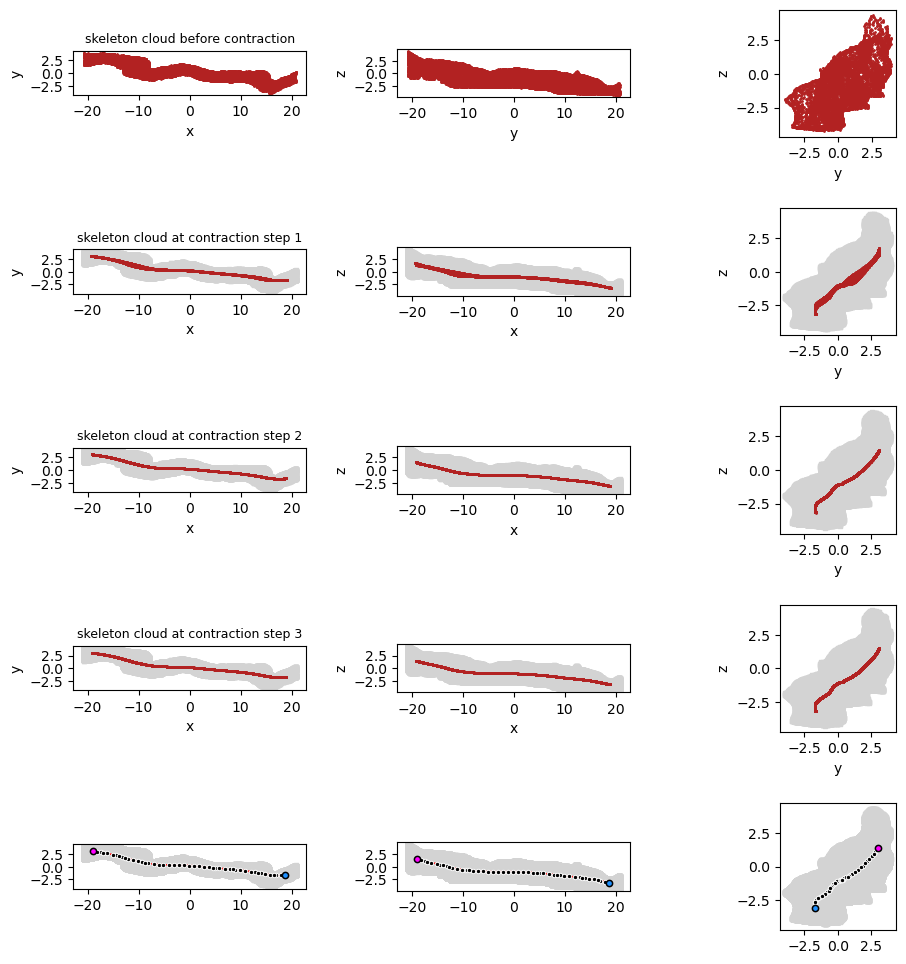

In [17]:

fig, axes = plt.subplots(5, 3, figsize= (10, 10)) 

# plot the first point cloud, before contraction. x y view 
axes[0, 0].scatter(*data.centroids[::75, [0, 1]].T, **skeleton_kwargs, label = "skeleton cloud\nbefore contraction")

axes[0, 0].set_aspect("equal")
axes[0, 0].set_xlabel("x")
axes[0, 0].set_ylabel("y")

# plot the first point cloud, before contraction. x z view 
axes[0, 1].scatter(*data.centroids[::75, [0, 2]].T, **skeleton_kwargs, label = "skeleton cloud\nbefore contraction")

axes[0, 1].set_aspect("equal")
axes[0, 1].set_xlabel("y")
axes[0, 1].set_ylabel("z")

# plot the first point cloud, before contraction. y z view 
axes[0, 2].scatter(*data.centroids[::75, [1, 2]].T, **skeleton_kwargs, label = "skeleton cloud\nbefore contraction")

axes[0, 2].set_aspect("equal")
axes[0, 2].set_xlabel("y")
axes[0, 2].set_ylabel("z")

k = 0
for cloud, (ax1,ax2,ax3) in zip(skeleton_clouds, axes[1:]):
    k+=1
    if k < 4:
        the_pcd = np.asarray(cloud.points)
        ax1.scatter(*the_pcd[:, [0, 1]].T, **skeleton_kwargs, label =f"skeleton cloud\nat contraction step {k}")
        ax1.scatter(*data.centroids[::20, [0, 1]].T, **mesh_kwargs)
        
        ax1.set_title(f"skeleton cloud at contraction step {k}", fontdict=dict(fontsize=9))
        ax1.set_aspect("equal")
        ax1.set_xlabel("x")
        ax1.set_ylabel("y")

        ax2.scatter(*the_pcd[:, [0, 2]].T, **skeleton_kwargs, label =f"skeleton cloud\nat contraction step {k}")
        ax2.scatter(*data.centroids[::20, [0, 2]].T, **mesh_kwargs)
        
        ax2.set_aspect("equal")
        ax2.set_xlabel("x")
        ax2.set_ylabel("z")


        ax3.scatter(*the_pcd[:, [1, 2]].T, **skeleton_kwargs)
        ax3.scatter(*data.centroids[::20, [1, 2]].T, **mesh_kwargs)
        
        ax3.set_aspect("equal")
        ax3.set_xlabel("y")
        ax3.set_ylabel("z")

axes[0, 0].set_title("skeleton cloud before contraction", fontdict=dict(fontsize=9))

## mesh and the LBC centreline. 

# plot the sparse cloud
axes[-1, 0].scatter(*out_LBC["sparse_cloud"][:, [0, 1]].T, **node_kwargs, label = "sparse contracted cloud")
# plot the LBC estimate of the centreline 
axes[-1, 0].plot(*LBC_ct[:, [0, 1]].T, **ct_kwargs, label = "centreline")
# plot the start and end point
axes[-1, 0].scatter(*P1[[0, 1]],**start_kwargs)
axes[-1, 0].scatter(*P2[[0, 1]],**end_kwargs)
# plot the mesh 
axes[-1, 0].scatter(*data.centroids[::5, [0, 1]].T, **mesh_kwargs)
axes[-1, 0].set_aspect("equal")

# plot the sparse cloud
axes[-1, 1].scatter(*out_LBC["sparse_cloud"][:, [0, 2]].T, **node_kwargs, label = "sparse contracted cloud")
# plot the LBC estimate of the centreline 
axes[-1, 1].plot(*LBC_ct[:, [0, 2]].T, **ct_kwargs, label = "centreline")
# plot the start and end point
axes[-1, 1].scatter(*P1[[0, 2]],**start_kwargs)
axes[-1, 1].scatter(*P2[[0, 2]],**end_kwargs)
# plot the mesh 
axes[-1, 1].scatter(*data.centroids[::5, [0, 2]].T, **mesh_kwargs)
axes[-1, 1].set_aspect("equal")

# plot the sparse cloud
axes[-1, 2].scatter(*out_LBC["sparse_cloud"][:, [1, 2]].T, **node_kwargs, label = "sparse contracted cloud")
# plot the LBC estimate of the centreline 
axes[-1, 2].plot(*LBC_ct[:, [1, 2]].T, **ct_kwargs, label = "centreline")
# plot the start and end point
axes[-1, 2].scatter(*P1[[1, 2]],**start_kwargs)
axes[-1, 2].scatter(*P2[[1, 2]],**end_kwargs)
# plot the mesh 
axes[-1, 2].scatter(*data.centroids[::5, [1, 2]].T, **mesh_kwargs)
axes[-1, 2].set_aspect("equal")

plt.tight_layout(pad = 2)
plt.savefig(f"../temp/{ID}_{CONDUIT_NAME}/lbc/{CONDUIT_NAME}_lbc_contraction_steps.png", dpi = 300)
plt.show()